# C3 · Clasificador **Inception-V4** (ajuste fino desde ImageNet)

Clasifica **recortes** de alimentos en las 323 clases ajustando Inception-V4 (`timm`, `inception_v4.tf_in1k`, pesos ImageNet-1k del TensorFlow original). Misma plantilla que C2: cambia solo el modelo y sus hiperparámetros de ajuste fino.

**El modelo.** 42.7 M de parámetros y 12.3 GMACs a 299×299 (unas 8 veces los parámetros de MobileNetV3-Large). Normalización propia de sus pesos: media = desviación = 0.5.

**Cómo se alimenta (todo desde tu Google Drive):**

| Archivo en Drive | Para qué |
|---|---|
| `food-prep-v21.zip` | Salida del 00: `classes.json`, `splits.json`, `crops_*.csv` y la carpeta **`crops/`** (los recortes) |
| `food_utils_v3.py` (o `_v2`) | Utilidades comunes con `CropDataset` (se copia como `food_utils.py`); si hay varias versiones en Drive se elige la más completa |

No necesita `food-recognition-2022.zip`. Los archivos se **buscan por nombre** en tu Drive (`calorie_counter` y `MyDrive`, hasta 3 niveles) y, si no están, se intentan bajar con `gdown`. Se extraen en el disco local de Colab (`/content/data`); los **pesos, el historial y los resultados** se guardan en Drive.

**Qué hace**
1. Comprueba `timm`, lista los Inception disponibles y lee la **normalización propia del modelo**.
2. Construye el backbone **sin cabeza** (`num_classes=0`), averigua la dimensión de sus características (1536) y le añade una cabeza nueva (promedio global + dropout + lineal a 323 clases); **prueba de humo** de la forma de salida antes de entrenar.
3. Ajusta con AdamW (LR distinto para backbone y cabeza), calentamiento + coseno, *label smoothing*, CutMix y AMP, con **reanudación segura** (guardando en Drive) y parada temprana.
4. Evalúa en val y test con las **mismas métricas, particiones y aumento de datos** que C1 y C2, guarda probabilidades y pesos, mide eficiencia y escribe `resultados/C3_*.json`.

> **Modo piloto (`pilot=True`, por defecto).** 1 época con el 5 % de los recortes y 300 recortes de val/test. Escribe en `resultados_pilot/`.

> **Espacio en Drive y progreso.** `best.pt` pesa ~0.2 GB y `last.pt` (modelo + optimizador) ~0.5 GB. `last.pt` se guarda en Drive **en cada época** (`ckpt_every=1`) con escritura atómica y se conserva una copia de seguridad (`last_prev.pt`, `keep_prev_ckpt=True`); ambos **se borran al terminar** y el historial queda en `history.json` y `history.csv`. Necesitas unos **2 GB libres** en Drive durante el entrenamiento.

> **Resolución.** Aquí `imgsz=224`. Inception-V4 reduce la entrada 32 veces mediante convoluciones sin relleno: a 299 px su último mapa es de 8×8; a 224 px, de 5×5; a 160 px, de solo 3×3, donde pierde gran parte de su diseño. Como los recortes miden ≤ 256 px, 224 no desperdicia información. **C1 y C2 se subirán manualmente a 224** para comparar los cuatro a igual tamaño; el tamaño queda anotado en los resultados (`cfg.imgsz`).

> **Equidad.** Mismo preprocesado de recortes (`fu.CropDataset`: letterbox cuadrado y aumento), particiones y métricas que C1/C2; difiere en la normalización (la del modelo). Parte de pesos ImageNet-1k (C1 no).


In [2]:
import os, sys, re, json, time, glob, random, shutil, subprocess, importlib
from pathlib import Path
import numpy as np

def ensure(pkg):
    try: importlib.import_module(pkg)
    except ImportError: subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)
for p in ("gdown", "timm"): ensure(p)
try:
    from tqdm.auto import tqdm
except ImportError:
    def tqdm(x, **kw): return x

try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    drive.mount("/content/drive")
    WORK = Path("/content/drive/MyDrive/calorie_counter")          # persiste entre sesiones (pesos, resultados)
    DATA = Path("/content/data")                                    # disco local: zips extraídos
elif Path("/kaggle/working").exists():
    WORK, DATA = Path("/kaggle/working/calorie_counter"), Path("/kaggle/working/data")
else:
    WORK, DATA = Path("./calorie_counter"), Path("./data")
WORK.mkdir(parents=True, exist_ok=True); DATA.mkdir(parents=True, exist_ok=True)
print("WORK (persistente):", WORK, "| DATA (local):", DATA)

Mounted at /content/drive
WORK (persistente): /content/drive/MyDrive/calorie_counter | DATA (local): /content/data


## 0. Datos desde Drive

Busca los tres archivos, extrae los dos zips en `DATA` (se omite si ya están extraídos en esta sesión) y localiza las carpetas que necesita `food_utils`. Si algún archivo tiene otro nombre o está en otra carpeta, indica su ruta en `DRIVE_PATHS`.

In [3]:
# Rutas explícitas (opcional). None = buscar por nombre en tu Drive.
DRIVE_PATHS = dict(prep=None, utils=None)
# Ids de los enlaces compartidos (solo se usan si el archivo no aparece en tu Drive montado)
DRIVE_IDS = dict(prep="1LmD3j5smb-1NJp4hV0yAagvb7__rT--A", utils="1kOnEiiynvPoBtNtxJtrfIpVJ0HlQTyha")
PATTERNS  = dict(prep=r"food[-_ ]?prep[-_ ]?v21.*\.zip$", utils=r"^food_utils.*\.py$")
OUT_NAMES = dict(prep="food-prep-v21.zip", utils="food_utils.py")

def find_in_drive(kind, max_depth=3):
    pat = re.compile(PATTERNS[kind], re.I)
    roots = [WORK, Path("/content/drive/MyDrive"), Path.cwd()]
    found = []
    for root in roots:
        if not root.exists(): continue
        base = len(root.parts)
        for dp, dn, fn in os.walk(root):
            dn[:] = [d for d in dn if not d.startswith(".") and d not in ("runs", "yolo_data", "predicciones", "resultados", "Trash")]
            if len(Path(dp).parts) - base >= max_depth: dn[:] = []
            for f in fn:
                if pat.search(f): found.append(Path(dp) / f)
    if not found: return None
    if kind == "utils" and len(found) > 1:
        # varias versiones de food_utils en Drive: se elige la más completa (CropDataset, rotación) y, a igualdad, la más reciente
        def score(p):
            try: t = p.read_text(encoding="utf-8", errors="ignore")
            except Exception: t = ""
            return ("class CropDataset" in t) + ("rotate: float" in t), p.stat().st_mtime
        found.sort(key=score, reverse=True)
        print("   versiones de food_utils en Drive:", [p.name for p in found], "→ se usa", found[0].name)
    return found[0]

def get_file(kind):
    if DRIVE_PATHS[kind]:
        p = Path(DRIVE_PATHS[kind]); assert p.exists(), f"No existe {p}"; return p
    p = find_in_drive(kind)
    if p: print(f"[{kind}] encontrado en Drive → {p}"); return p
    out = DATA / "zips" / OUT_NAMES[kind]; out.parent.mkdir(parents=True, exist_ok=True)
    print(f"[{kind}] no está en el Drive montado; intento bajarlo con gdown (id {DRIVE_IDS[kind]})...")
    import gdown
    r = gdown.download(id=DRIVE_IDS[kind], output=str(out), quiet=False)
    if not r or not out.exists():
        raise RuntimeError(f"No pude obtener '{kind}'. Copia el archivo a tu Drive (carpeta {WORK}) o indica su ruta en DRIVE_PATHS "
                           f"(gdown falla a menudo en archivos grandes por la cuota de descargas de Drive).")
    return out

def unzip_once(zpath, dest, exclude=()):
    zpath, dest = Path(zpath), Path(dest)
    marker, sig = dest / ".unzipped_ok", f"{zpath.name}:{zpath.stat().st_size}:{sorted(exclude)}"
    if marker.exists() and marker.read_text() == sig:
        print(f"   ya extraído en {dest}"); return
    dest.mkdir(parents=True, exist_ok=True)
    free, need = shutil.disk_usage(dest).free, zpath.stat().st_size
    print(f"   zip {need/1e9:.2f} GB | espacio libre {free/1e9:.1f} GB")
    if free < 1.5 * need: print("   ⚠️ poco espacio libre para extraer; si falla, usa un entorno con más disco")
    t0 = time.time()
    if shutil.which("unzip"):
        r = subprocess.run(["unzip", "-q", "-o", str(zpath), "-d", str(dest)] + (["-x", *exclude] if exclude else []))
        if r.returncode > 1: raise RuntimeError(f"unzip falló (código {r.returncode})")
    else:
        import zipfile, fnmatch
        with zipfile.ZipFile(zpath) as z:
            for n in tqdm(z.namelist(), desc="extrayendo"):
                if not any(fnmatch.fnmatch(n, p) for p in exclude): z.extract(n, dest)
    marker.write_text(sig); print(f"   extraído en {time.time()-t0:.0f} s")

def find_dir(root, pred, max_depth=5):
    root = Path(root); base = len(root.parts)
    for dp, dn, fn in os.walk(root):
        dn[:] = [d for d in dn if d != "images"]
        if len(Path(dp).parts) - base >= max_depth: dn[:] = []
        if pred(dn, fn): return Path(dp)
    return None

# 1) salida del cuadernillo 00, CON los recortes (C1 los necesita)
z_prep = get_file("prep"); print("→ extrayendo food-prep-v21 (con recortes; puede tardar unos minutos)"); unzip_once(z_prep, DATA / "prep")
PREP_DIR = find_dir(DATA / "prep", lambda dn, fn: "classes.json" in fn and "splits.json" in fn)
assert PREP_DIR is not None, "El zip de prep no contiene classes.json + splits.json"
missing = [f for f in ("manifest.json", "crops_train.csv", "crops_val.csv", "crops_test.csv") if not (PREP_DIR / f).exists()]
assert not missing, f"Faltan archivos en {PREP_DIR}: {missing}"
assert (PREP_DIR / "crops").exists(), f"Falta la carpeta de recortes {PREP_DIR / 'crops'}: ¿el zip es food-prep-v21 completo?"

# 2) food_utils
u = get_file("utils"); CODE = DATA / "code"; CODE.mkdir(exist_ok=True); shutil.copy(u, CODE / "food_utils.py")
sys.path.insert(0, str(CODE)); sys.modules.pop("food_utils", None)
print("\nPREP_DIR:", PREP_DIR, "\nutils   :", CODE / "food_utils.py")

[prep] no está en el Drive montado; intento bajarlo con gdown (id 1LmD3j5smb-1NJp4hV0yAagvb7__rT--A)...


Downloading...
From (original): https://drive.google.com/uc?id=1LmD3j5smb-1NJp4hV0yAagvb7__rT--A
From (redirected): https://drive.google.com/uc?id=1LmD3j5smb-1NJp4hV0yAagvb7__rT--A&confirm=t&uuid=ab8bc6fa-dedf-4529-91e9-3be4be42a9df
To: /content/data/zips/food-prep-v21.zip
100%|██████████| 2.46G/2.46G [00:27<00:00, 89.7MB/s]


→ extrayendo food-prep-v21 (con recortes; puede tardar unos minutos)
   zip 2.46 GB | espacio libre 204.9 GB
   extraído en 35 s
   versiones de food_utils en Drive: ['food_utils_v3.py', 'food_utils_v3.py', 'food_utils_v2.py', 'food_utils_v2.py', 'food_utils.py', 'food_utils.py'] → se usa food_utils_v3.py
[utils] encontrado en Drive → /content/drive/MyDrive/DataSets/food_utils_v3.py

PREP_DIR: /content/data/prep 
utils   : /content/data/code/food_utils.py


In [4]:
# Comprobar que el bloque de descarga se ejecutó antes
for _n in ("PREP_DIR", "CODE"):
    assert _n in globals(), f"Falta {_n}: ejecuta primero el bloque de descarga de datos (sección 0)."
assert (CODE / "food_utils.py").exists(), f"No está {CODE / 'food_utils.py'}"
if str(CODE) not in sys.path: sys.path.insert(0, str(CODE))
sys.modules.pop("food_utils", None)
import food_utils as fu

CFG = dict(
    base_id    = "C3",
    arch       = "inception_v4.tf_in1k",      # cualquier modelo de timm
    pretrained = True,
    min_timm   = "1.0.0",
    imgsz      = 224,         # Inception-V4 se diseñó para 299; a 160 su último mapa sería de 3x3. Poner el MISMO valor en C1–C4
    batch      = 64,
    eval_batch = 128,
    epochs     = 20,
    patience   = 5,
    lr_backbone = 1e-4,
    lr_head    = 1e-3,
    weight_decay = 0.05,
    warmup_iters = 300,
    label_smoothing = 0.1,
    aug_rot    = 15,          # rotación aleatoria en [-x, +x] grados (0 = desactivada); requiere food_utils_v3. MISMO valor en C1–C4
    cutmix_prob = 0.0,        # igual que C1/C2
    dropout    = 0.2,
    grad_clip  = 1.0,
    amp        = "auto",      # auto | bf16 | fp16 | off
    ckpt_every = 1,           # guardar last.pt en Drive cada N épocas (~0.5 GB con este modelo)
    keep_prev_ckpt = True,    # conserva last_prev.pt (copia de seguridad; barato con este modelo)
    cleanup_last = True,      # borrar last.pt al terminar (el historial queda en history.json)
    workers    = min(8, os.cpu_count() or 2),
    seed       = 42,
    n_boot     = 1000,
    log_every  = 100,
    pilot      = False,        # <-- False para el entrenamiento real
    prep_dir   = str(PREP_DIR),   # carpeta extraída por el bloque de descarga
)
CFG["exp_id"] = f"{CFG['base_id']}_{CFG['arch'].split('.')[0]}"
RUN_NAME = CFG["exp_id"] + ("_pilot" if CFG["pilot"] else "")
print("food_utils", fu.__version__, "| Experimento:", RUN_NAME, "| arquitectura:", CFG["arch"])

food_utils 0.1.0 | Experimento: C3_inception_v4 | arquitectura: inception_v4.tf_in1k


In [5]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
CUDA = torch.cuda.is_available()
DEVICE = "cuda" if CUDA else "cpu"
GPU = torch.cuda.get_device_name(0) if CUDA else "cpu"
AMP = CFG["amp"]
if AMP == "auto": AMP = ("bf16" if torch.cuda.is_bf16_supported() else "fp16") if CUDA else "off"
AMP_DTYPE = {"bf16": torch.bfloat16, "fp16": torch.float16}.get(AMP, torch.float16)

def ensure_timm():
    import timm
    from packaging.version import Version
    if Version(timm.__version__) < Version(CFG["min_timm"]):
        print(f"timm {timm.__version__} < {CFG['min_timm']}: actualizando…")
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-U", "timm"], check=True)
        import importlib.metadata as md
        importlib.invalidate_caches()
        if Version(md.version("timm")) >= Version(CFG["min_timm"]):
            raise RuntimeError(f"timm actualizado a {md.version('timm')}: reinicia el entorno (Entorno de ejecución → Reiniciar) y vuelve a ejecutar.")
        print("⚠️ No se pudo obtener una versión más reciente de timm; se continúa con", timm.__version__)
    return timm
timm = ensure_timm()
print("torch", torch.__version__, "| timm", timm.__version__, "| dispositivo:", GPU, "| AMP:", AMP)
if not CUDA: print("⚠️ Sin GPU: el entrenamiento real no es viable. Activa una GPU.")
try:
    print("Inception en esta versión de timm:", timm.list_models("inception*"), "| con pesos:", timm.list_pretrained("inception_v4*"))
except Exception as e:
    print("No se pudo listar los modelos Inception:", e)

# Normalización propia del modelo (la de sus pesos): no asumir la de ImageNet
try:
    PCFG = timm.models.get_pretrained_cfg(CFG["arch"])
    MEAN = tuple(getattr(PCFG, "mean", None) or fu.IMAGENET_MEAN); STD = tuple(getattr(PCFG, "std", None) or fu.IMAGENET_STD)
    print(f"Config de preentrenamiento: mean={MEAN} std={STD} input_size={getattr(PCFG, 'input_size', None)}")
except Exception as e:
    PCFG, MEAN, STD = None, tuple(fu.IMAGENET_MEAN), tuple(fu.IMAGENET_STD)
    print("⚠️ No se pudo leer la config de preentrenamiento; se usa la normalización de ImageNet:", e)

fu.set_seed(CFG["seed"])
prep = fu.Prep(CFG["prep_dir"])
print(prep.summary())
K = prep.K
CROPS = {s: prep.crops(s) for s in ("train", "val", "test")}
print({s: len(d) for s, d in CROPS.items()}, "recortes | clases:", K)
# Comprobar que los recortes existen en disco (la extracción debe incluir la carpeta crops/)
for s, d in CROPS.items():
    need = {"file", "class_idx", "ann_id", "area_frac"} - set(d.columns)
    assert not need, f"crops_{s}.csv no tiene las columnas {need}"
    miss = [f for f in d["file"].sample(min(200, len(d)), random_state=0) if not Path(f).exists()]
    assert not miss, f"Faltan recortes de {s} (p. ej. {miss[0]}). Borra {DATA / 'prep'} y vuelve a ejecutar la sección 0."
print("✅ Recortes verificados en disco")
EPOCHS = 1 if CFG["pilot"] else CFG["epochs"]
TRAIN_LIMIT = int(0.05 * len(CROPS["train"])) if CFG["pilot"] else None
EVAL_LIMIT = 300 if CFG["pilot"] else None
FINAL_LIMIT = 300 if CFG["pilot"] else None

torch 2.11.0+cu130 | timm 1.0.30 | dispositivo: Tesla T4 | AMP: bf16
Inception en esta versión de timm: ['inception_next_atto', 'inception_next_base', 'inception_next_small', 'inception_next_tiny', 'inception_resnet_v2', 'inception_v3', 'inception_v4'] | con pesos: ['inception_v4.tf_in1k']
Config de preentrenamiento: mean=(0.5, 0.5, 0.5) std=(0.5, 0.5, 0.5) input_size=(3, 299, 299)
Prep[/content/data/prep] K=323 imagenes={'train': 35195, 'test': 3911, 'val': 946} anotaciones={'train': 66033, 'test': 7405, 'val': 1708} splits_hash=ce6d6fb977abcfd4
{'train': 65300, 'val': 1669, 'test': 7301} recortes | clases: 323
✅ Recortes verificados en disco


In [6]:
# CropDataset viene en food_utils (v2/v3): MISMO preprocesado y aumento para C1–C4 (sub-recorte aleatorio, volteo,
# brillo/contraste/saturación ±25 %, letterbox cuadrado con relleno gris; v3 añade rotación opcional).
assert hasattr(fu, "CropDataset"), ("Tu food_utils no incluye CropDataset. Copia food_utils_v2.py o food_utils_v3.py a Drive "
                                    f"({WORK}), borra las versiones antiguas y reinicia el entorno.")
import inspect
ROT_OK = "rotate" in inspect.signature(fu.CropDataset.__init__).parameters
if CFG.get("aug_rot", 0) > 0 and not ROT_OK:
    print("⚠️ Esta food_utils no soporta rotación (usa food_utils_v3.py). Se entrena SIN rotación; para que C1–C4 sean comparables, usa la misma versión en todos.")
print("food_utils", fu.__version__, "| rotación:", f"±{CFG['aug_rot']}°" if ROT_OK and CFG.get("aug_rot", 0) > 0 else "desactivada")

def crop_ds(df, train, mean=None, std=None):
    """Dataset de recortes con el preprocesado común de food_utils (mean/std = normalización del modelo; ImageNet si None)."""
    kw = {k: v for k, v in (("mean", mean), ("std", std)) if v is not None}
    if train and ROT_OK and CFG.get("aug_rot", 0) > 0: kw["rotate"] = CFG["aug_rot"]
    return fu.CropDataset(df, CFG["imgsz"], train=train, **kw)

_t = crop_ds(CROPS["val"].head(2), True)[0]; print("Muestra:", tuple(_t[0].shape), "clase", _t[1])

food_utils 0.1.0 | rotación: ±15°
Muestra: (3, 224, 224) clase 223


## 1. Modelo, datos y bucle de entrenamiento

`build_model` crea el backbone de `timm` **sin cabeza** (`num_classes=0`), averigua la dimensión de sus características con una pasada de prueba en CPU y le añade nuestra cabeza (global average pooling si hace falta + dropout + lineal). Así no depende de cómo cada modelo organiza su clasificador.

In [7]:
def autocast():
    return torch.autocast(device_type="cuda", dtype=AMP_DTYPE, enabled=(AMP != "off" and CUDA))

class TimmClassifier(nn.Module):
    def __init__(self, backbone, feat_dim, num_classes, dropout):
        super().__init__()
        self.backbone, self.drop, self.fc = backbone, nn.Dropout(dropout), nn.Linear(feat_dim, num_classes)
    def forward(self, x):
        f = self.backbone(x)
        if f.ndim == 4: f = f.mean((2, 3))          # mapa de características -> vector
        elif f.ndim == 3: f = f.mean(1)             # secuencia de tokens -> vector
        return self.fc(self.drop(f))

def build_model():
    pre = CFG["pretrained"] and not CFG["arch"].endswith(".untrained")
    attempts = [dict(num_classes=0, global_pool="avg"), dict(num_classes=0)]             # reintenta sin los argumentos que el modelo no admita
    backbone, err = None, None
    for kw in attempts:
        try: backbone = timm.create_model(CFG["arch"], pretrained=pre, **kw); break
        except TypeError as e: err = e
    if backbone is None: raise RuntimeError(f"No se pudo crear {CFG['arch']}: {err}")
    S = CFG["imgsz"]
    with torch.no_grad():
        was = backbone.training; backbone.eval(); f = backbone(torch.zeros(1, 3, S, S)); backbone.train(was)
    feat = f.shape[1] if f.ndim == 4 else f.shape[-1]
    model = TimmClassifier(backbone, feat, K, CFG["dropout"])
    return model.to(DEVICE).to(memory_format=torch.channels_last)

def smoke_test(model):
    S = CFG["imgsz"]; was = model.training; model.eval()
    with torch.no_grad(), autocast(): out = model(torch.zeros(2, 3, S, S).to(DEVICE).to(memory_format=torch.channels_last))
    model.train(was)
    assert tuple(out.shape) == (2, K), f"Salida inesperada {tuple(out.shape)}; se esperaba (2, {K})"
    print(f"Prueba de humo OK: salida {tuple(out.shape)} | parámetros: {sum(p.numel() for p in model.parameters())/1e6:.1f} M")

def _to_dev(x): return x.to(DEVICE, non_blocking=True).to(memory_format=torch.channels_last)

def make_train_loader():
    df = CROPS["train"]
    if TRAIN_LIMIT: df = df.sample(TRAIN_LIMIT, random_state=CFG["seed"])
    return DataLoader(crop_ds(df, True, MEAN, STD), batch_size=CFG["batch"], shuffle=True,
                      num_workers=CFG["workers"], drop_last=True, pin_memory=CUDA, persistent_workers=CFG["workers"] > 0)

def build_optimizer(model):
    groups = {}
    for n, p in model.named_parameters():
        if not p.requires_grad: continue
        groups.setdefault((n.startswith("backbone."), p.ndim <= 1), []).append(p)
    pg = [dict(params=ps, lr=CFG["lr_backbone"] if bb else CFG["lr_head"], weight_decay=0.0 if nd else CFG["weight_decay"])
          for (bb, nd), ps in groups.items()]
    return torch.optim.AdamW(pg, lr=CFG["lr_head"])

def build_scheduler(optimizer, total_steps):
    return torch.optim.lr_scheduler.LambdaLR(optimizer, lambda s: fu.warmup_cosine(s, total_steps, CFG["warmup_iters"]))

def build_scaler():
    try: return torch.amp.GradScaler("cuda", enabled=(AMP == "fp16"))
    except (AttributeError, TypeError): return torch.cuda.amp.GradScaler(enabled=(AMP == "fp16"))

def save_ckpt(path, obj):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.name + ".tmp"); torch.save(obj, tmp); os.replace(tmp, path)

def load_ckpt(path):
    try: return torch.load(path, map_location="cpu", weights_only=False)
    except TypeError: return torch.load(path, map_location="cpu")

def train_one_epoch(model, loader, optimizer, scheduler, scaler, epoch):
    model.train(); crit = nn.CrossEntropyLoss(label_smoothing=CFG["label_smoothing"]); tot, n, t0 = 0.0, 0, time.time()
    for it, (x, y, _) in enumerate(loader):
        x, y = _to_dev(x), y.to(DEVICE, non_blocking=True)
        cut = CFG["cutmix_prob"] > 0 and random.random() < CFG["cutmix_prob"]
        if cut:
            lam = float(np.random.beta(1.0, 1.0)); idx = torch.randperm(x.size(0), device=x.device)
            H, W = x.shape[2], x.shape[3]; rh, rw = int(H * np.sqrt(1 - lam)), int(W * np.sqrt(1 - lam))
            cy, cx = np.random.randint(H), np.random.randint(W)
            y0, y1, x0, x1 = max(cy - rh // 2, 0), min(cy + rh // 2, H), max(cx - rw // 2, 0), min(cx + rw // 2, W)
            x[:, :, y0:y1, x0:x1] = x[idx, :, y0:y1, x0:x1]
            lam = 1.0 - (y1 - y0) * (x1 - x0) / (H * W)
        with autocast():
            out = model(x)
            loss = lam * crit(out, y) + (1 - lam) * crit(out, y[idx]) if cut else crit(out, y)
        optimizer.zero_grad(set_to_none=True)
        if not torch.isfinite(loss):
            print(f"  ⚠️ pérdida no finita en la iteración {it}; se omite"); scheduler.step(); continue
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer); torch.nn.utils.clip_grad_norm_(model.parameters(), CFG["grad_clip"])
        scaler.step(optimizer); scaler.update(); scheduler.step()
        tot += float(loss); n += 1
        if (it + 1) % CFG["log_every"] == 0:
            print(f"  época {epoch} it {it+1}/{len(loader)} | pérdida {tot/max(1,n):.3f} | lr {optimizer.param_groups[0]['lr']:.2e} | {time.time()-t0:.0f} s")
    return tot / max(1, n)

@torch.no_grad()
def predict_probs(model, split, limit=None):
    model.eval(); df = CROPS[split]
    if limit: df = df.sample(min(limit, len(df)), random_state=0)
    dl = DataLoader(crop_ds(df, False, MEAN, STD), batch_size=CFG["eval_batch"], shuffle=False, num_workers=CFG["workers"])
    ids, ys, ps = [], [], []
    for x, y, aid in dl:
        with autocast(): logits = model(_to_dev(x))
        ps.append(logits.float().softmax(-1).cpu().numpy()); ys.append(y.numpy()); ids.append(aid.numpy())
    return np.concatenate(ids), np.concatenate(ys), np.concatenate(ps)

def evaluate_val(model):
    ids, y, p = predict_probs(model, "val", limit=EVAL_LIMIT)
    m = fu.classification_metrics(y, p)
    print(f"    val: top1 {m['top1']:.4f} | top5 {m['top5']:.4f} | macro-F1 {m['macro_f1']:.4f}")
    return m["top1"]

## 2. Entrenamiento con reanudación segura

Si existe `DONE.json` no se entrena de nuevo; si hay `last.pt` sin `DONE.json` se **reanuda** (si se corta entre dos checkpoints, se repiten las épocas posteriores al último guardado). El historial se escribe en `history.json` en cada época.

In [8]:
RUN_DIR = WORK / "runs" / RUN_NAME                      # en Drive: sobrevive a las desconexiones
RUN_DIR.mkdir(parents=True, exist_ok=True)
CK_LAST, CK_PREV, CK_BEST, DONE, HIST = RUN_DIR / "last.pt", RUN_DIR / "last_prev.pt", RUN_DIR / "best.pt", RUN_DIR / "DONE.json", RUN_DIR / "history.json"
HIST_CSV = RUN_DIR / "history.csv"
(RUN_DIR / "config.json").write_text(json.dumps(CFG, indent=1, default=str))
KEY_CFG = ("arch", "imgsz", "batch", "epochs", "lr_backbone", "lr_head", "weight_decay", "label_smoothing", "cutmix_prob",
           "dropout", "aug_rot", "seed")

def save_last(obj):
    """Escritura atómica (tmp + replace). Con keep_prev_ckpt, rota last.pt -> last_prev.pt antes de escribir."""
    if CFG["keep_prev_ckpt"] and CK_LAST.exists(): os.replace(CK_LAST, CK_PREV)
    save_ckpt(CK_LAST, obj)

def load_last():
    for p in (CK_LAST, CK_PREV):
        if p.exists():
            try:
                ck = load_ckpt(p); print(f"↻ Punto de reanudación: {p.name} (época {ck['epoch']+1} completada)"); return ck
            except Exception as e:
                print(f"⚠️ {p.name} ilegible ({type(e).__name__}: {e}); pruebo la copia anterior")
                if p == CK_LAST: CK_LAST.unlink()            # evita que una copia corrupta pise la buena al rotar
    return None

def run_training():
    model = build_model(); smoke_test(model)
    optimizer = build_optimizer(model)
    loader = make_train_loader()
    scheduler, scaler = build_scheduler(optimizer, EPOCHS * len(loader)), build_scaler()
    stopper, history, start = fu.EarlyStopper(CFG["patience"]), [], 0
    ck = load_last()
    if ck is not None:
        model.load_state_dict(ck["model"]); optimizer.load_state_dict(ck["optimizer"])
        scheduler.load_state_dict(ck["scheduler"]); scaler.load_state_dict(ck["scaler"])
        stopper.load_state_dict(ck["stopper"]); history, start = ck["history"], ck["epoch"] + 1
        diff = [k for k in KEY_CFG if ck.get("cfg") and str(ck["cfg"].get(k)) != str(CFG.get(k))]
        if diff: print("⚠️ CFG distinto del run original en", diff, "→ se usan los valores actuales (restaura los originales para reproducir fielmente)")
        print(f"   continúa en la época {start+1}/{EPOCHS} ({len(history)} ya hechas)")
    for epoch in range(start, EPOCHS):
        if stopper.should_stop: print("Parada temprana ya alcanzada antes del corte."); break
        t0 = time.time()
        loss = train_one_epoch(model, loader, optimizer, scheduler, scaler, epoch)
        t_train = time.time() - t0
        val_top1 = evaluate_val(model)
        improved = stopper.update(val_top1)
        if improved: save_ckpt(CK_BEST, dict(model=model.state_dict(), epoch=epoch, val_top1=val_top1))
        history.append(dict(epoch=epoch, loss=float(loss), val_top1=float(val_top1), lr=float(optimizer.param_groups[0]["lr"]),
                            train_s=round(t_train, 1), time_s=round(time.time() - t0, 1)))
        HIST.write_text(json.dumps(history)); pd.DataFrame(history).to_csv(HIST_CSV, index=False)     # historial legible, en Drive, tras cada época
        saved = (epoch + 1) % CFG["ckpt_every"] == 0 or stopper.should_stop or epoch == EPOCHS - 1
        if saved:
            save_last(dict(model=model.state_dict(), optimizer=optimizer.state_dict(), scheduler=scheduler.state_dict(),
                           scaler=scaler.state_dict(), stopper=stopper.state_dict(), history=history, epoch=epoch,
                           cfg={k: CFG[k] for k in KEY_CFG}))
        print(f"Época {epoch+1}/{EPOCHS} | pérdida {loss:.3f} | top-1 val {val_top1:.4f}{' ★' if improved else ''} | "
              f"{history[-1]['time_s']:.0f} s (entrenar {t_train:.0f} s){' | 💾 last.pt en Drive' if saved else ''}")
        if stopper.should_stop: print(f"Parada temprana: sin mejora en {CFG['patience']} épocas (mejor: época {stopper.best_epoch+1})"); break
    return history, stopper

import pandas as pd
if DONE.exists():
    print("✅ Entrenamiento ya terminado:", DONE.read_text()[:300])
else:
    history, stopper = run_training()
    DONE.write_text(json.dumps(dict(time_s=round(sum(h["time_s"] for h in history), 1), epochs_run=len(history),
                                    best_epoch=stopper.best_epoch, best_val_top1=stopper.best, pilot=CFG["pilot"],
                                    finished=time.strftime("%Y-%m-%d %H:%M:%S"))))
    if CFG["cleanup_last"] and not CFG["pilot"]:
        for _p in (CK_LAST, CK_PREV):
            if _p.exists(): _p.unlink()
        print("last.pt borrado (espacio en Drive); el historial queda en history.json / history.csv")
    if CFG["pilot"] and history:
        est = history[-1]["train_s"] / 0.05 / 60
        print(f"≈ {est:.1f} min de ENTRENAMIENTO por época con todos los recortes (+ validación) → {CFG['epochs']} épocas ≈ {est*CFG['epochs']/60:.1f} h")
INFO = json.loads(DONE.read_text()); assert CK_BEST.exists(), f"No existe {CK_BEST}"
print("Entrenamiento:", INFO)
if CUDA: torch.cuda.empty_cache()

model.safetensors: reconstructing file:   0%|          |  0.00B /  171MB            

model.safetensors: downloading bytes:           |  0.00B            

Prueba de humo OK: salida (2, 323) | parámetros: 41.6 M
↻ Punto de reanudación: last.pt (época 2 completada)
   continúa en la época 3/20 (2 ya hechas)


/tmp/ipykernel_1448/809830513.py:89: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  tot += float(loss); n += 1


  época 2 it 100/1020 | pérdida 2.343 | lr 9.79e-05 | 254 s
  época 2 it 200/1020 | pérdida 2.281 | lr 9.77e-05 | 508 s
  época 2 it 300/1020 | pérdida 2.219 | lr 9.75e-05 | 762 s
  época 2 it 400/1020 | pérdida 2.141 | lr 9.72e-05 | 1016 s
  época 2 it 500/1020 | pérdida 2.099 | lr 9.70e-05 | 1270 s
  época 2 it 600/1020 | pérdida 2.068 | lr 9.67e-05 | 1523 s
  época 2 it 700/1020 | pérdida 2.030 | lr 9.64e-05 | 1777 s
  época 2 it 800/1020 | pérdida 1.991 | lr 9.61e-05 | 2031 s
  época 2 it 900/1020 | pérdida 1.965 | lr 9.58e-05 | 2285 s
  época 2 it 1000/1020 | pérdida 1.938 | lr 9.55e-05 | 2539 s
    val: top1 0.4452 | top5 0.7304 | macro-F1 0.2688
Época 3/20 | pérdida 1.936 | top-1 val 0.4452 | 2615 s (entrenar 2590 s) | 💾 last.pt en Drive
  época 3 it 100/1020 | pérdida 2.800 | lr 9.51e-05 | 255 s
  época 3 it 200/1020 | pérdida 2.793 | lr 9.47e-05 | 509 s
  época 3 it 300/1020 | pérdida 2.765 | lr 9.44e-05 | 763 s
  época 3 it 400/1020 | pérdida 2.771 | lr 9.40e-05 | 1016 s
  ép

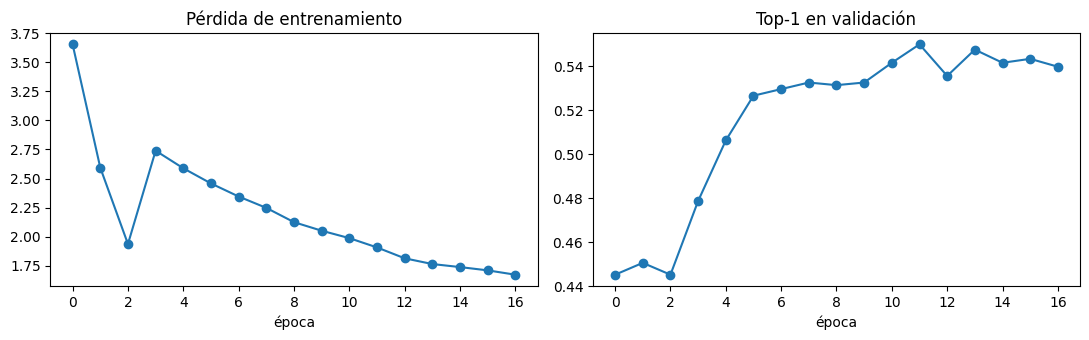

In [9]:
# Curvas de entrenamiento (history.json)
try:
    import matplotlib.pyplot as plt
    hist = json.loads(HIST.read_text())
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
    ax[0].plot([h["loss"] for h in hist], marker="o"); ax[0].set_title("Pérdida de entrenamiento")
    ax[1].plot([h["val_top1"] for h in hist], marker="o"); ax[1].set_title("Top-1 en validación")
    for a in ax: a.set_xlabel("época")
    plt.tight_layout(); plt.savefig(RUN_DIR / "curvas.png", dpi=130); plt.show()
except Exception as e:
    print("Sin curvas:", type(e).__name__, e)

---
### ✅ Fin del entrenamiento

Aquí termina la parte de **entrenamiento**: los pesos quedan en `{WORK}/runs/{RUN_NAME}/best.pt` y el historial en `history.csv` (en tu Drive). Las secciones 3–5 siguientes (evaluación, eficiencia y `resultados/C3_*.json`) se pueden ejecutar después y repetir sin reentrenar: el marcador `DONE.json` evita volver a entrenar.

## 3. Evaluación (val y test)

Se carga `best.pt`. Mismas métricas que C1: top-1, top-5, macro-F1, recall balanceado, F1 por clase, confusiones frecuentes e **IC 95 % por bootstrap** en test. Las probabilidades se guardan para el pipeline (cuadernillo 99).

In [10]:
PRED_DIR = WORK / ("predicciones_pilot" if CFG["pilot"] else "predicciones"); PRED_DIR.mkdir(parents=True, exist_ok=True)
model = build_model()
model.load_state_dict(load_ckpt(CK_BEST)["model"]); model.eval()

METRICS, OUTS, OUT_FILES = {}, {}, {}
for s in ("val", "test"):
    t0 = time.time()
    ids, y, p = predict_probs(model, s, limit=FINAL_LIMIT)
    m = fu.classification_metrics(y, p, names=prep.names)
    if s == "test": m["bootstrap_ci"] = fu.bootstrap_ci(y, p, n_boot=(100 if CFG["pilot"] else CFG["n_boot"]), seed=CFG["seed"])
    METRICS[s], OUTS[s] = m, (ids, y, p)
    OUT_FILES[s] = str(fu.save_classifier_outputs(PRED_DIR / f"{RUN_NAME}_{s}.npz", ids, y, p))
    print(f"[{s}] n={m['n']:,} | top-1 {m['top1']:.4f} | top-5 {m['top5']:.4f} | macro-F1 {m['macro_f1']:.4f} | recall balanceado {m['balanced_acc']:.4f} | {time.time()-t0:.0f} s")
ci = METRICS["test"]["bootstrap_ci"]
print("IC 95 % (test):", {k: f"{v['mean']:.3f} [{v['lo']:.3f}, {v['hi']:.3f}]" for k, v in ci.items()})
print("\nConfusiones más frecuentes (test):")
for c in METRICS["test"]["top_confusions"][:8]: print(f"  {c['true']}  →  {c['pred']}  ({c['count']})")

# Estadísticas completas en Drive (por clase, matriz de confusión completa y todas las métricas)
import pandas as pd
for s in ("val", "test"):
    pd.DataFrame(METRICS[s]["per_class"]).to_csv(PRED_DIR / f"{RUN_NAME}_{s}_por_clase.csv", index=False)
    _, y_, p_ = OUTS[s]
    np.savez_compressed(PRED_DIR / f"{RUN_NAME}_{s}_confusion.npz", cm=np.bincount(np.asarray(y_) * K + p_.argmax(1), minlength=K * K).reshape(K, K),
                        names=np.array(prep.names))
(PRED_DIR / f"{RUN_NAME}_metricas.json").write_text(json.dumps(fu._jsonable(METRICS), indent=1, ensure_ascii=False))
print("Estadísticas guardadas en:", PRED_DIR)

import pandas as pd
ids, y, p = OUTS["test"]; hit = pd.Series((p.argmax(1) == y).astype(float), index=ids)
tdf = CROPS["test"].set_index("ann_id").loc[ids]
tdf["hit"] = hit.values
try:
    tdf["tamaño"] = pd.qcut(tdf["area_frac"], 4, labels=["Q1 pequeña", "Q2", "Q3", "Q4 grande"], duplicates="drop")
    print("\nTop-1 por tamaño relativo de la instancia (test):"); print(tdf.groupby("tamaño", observed=True)["hit"].agg(["mean", "count"]).round(3).to_string())
except Exception as e:
    print("Sin análisis por tamaño:", type(e).__name__, e)

[val] n=1,669 | top-1 0.5500 | top-5 0.8113 | macro-F1 0.3922 | recall balanceado 0.4125 | 26 s
[test] n=7,301 | top-1 0.5776 | top-5 0.8350 | macro-F1 0.4269 | recall balanceado 0.4185 | 111 s
IC 95 % (test): {'top1': '0.578 [0.566, 0.590]', 'top5': '0.835 [0.827, 0.843]', 'macro_f1': '0.418 [0.402, 0.435]'}

Confusiones más frecuentes (test):
  espresso  →  coffee  (39)
  salad_leaf_salad_green  →  mixed_salad_chopped_without_sauce  (33)
  white_coffee  →  coffee  (31)
  coffee  →  espresso  (28)
  bread  →  bread_wholemeal  (23)
  mixed_salad_chopped_without_sauce  →  salad_leaf_salad_green  (21)
  bread_wholemeal  →  bread  (20)
  water  →  tea  (16)
Estadísticas guardadas en: /content/drive/MyDrive/calorie_counter/predicciones

Top-1 por tamaño relativo de la instancia (test):
             mean  count
tamaño                  
Q1 pequeña  0.490   1827
Q2          0.562   1824
Q3          0.633   1827
Q4 grande   0.625   1823


## 4. Eficiencia

Solo el **clasificador**: pasada hacia delante con 1 recorte preprocesado (latencia) y con un lote de 128 (rendimiento), en la GPU de esta sesión. Solo comparable entre modelos medidos en la **misma GPU** y con la misma precisión numérica (se anota).

In [11]:
S = CFG["imgsz"]; x1 = torch.randn(1, 3, S, S, device=DEVICE).to(memory_format=torch.channels_last)
xb = torch.randn(128, 3, S, S, device=DEVICE).to(memory_format=torch.channels_last)
@torch.no_grad()
def fwd1():
    with autocast(): model(x1)
@torch.no_grad()
def fwdb():
    with autocast(): model(xb)
fu.reset_gpu_peak()
LAT = fu.measure_latency(fwd1, warmup=20, iters=100)
THR = fu.measure_latency(fwdb, warmup=5, iters=20)
EFF = dict(params=fu.count_params(model), latency=LAT, throughput_img_s=128 / (THR["mean_ms"] / 1000), gpu_mem_mb=fu.gpu_memory_mb(),
           gpu=GPU, imgsz=S, precision=AMP, scope="forward del clasificador (batch 1 / batch 128), sin carga de imagen")
print(f"Parámetros: {EFF['params']/1e6:.2f} M | latencia (batch 1): {LAT['mean_ms']:.2f} ± {LAT['std_ms']:.2f} ms | rendimiento: {EFF['throughput_img_s']:,.0f} img/s en {GPU} [{AMP}]")

Parámetros: 41.64 M | latencia (batch 1): 30.55 ± 2.17 ms | rendimiento: 69 img/s en Tesla T4 [bf16]


## 5. Guardar resultados

In [12]:
OUT_RES = WORK / ("resultados_pilot" if CFG["pilot"] else "resultados")
res_path = fu.write_result(
    RUN_NAME, model=f"timm {CFG['arch']}", metrics=METRICS, prep=prep, cfg=CFG, seed=CFG["seed"], efficiency=EFF,
    train=dict(pretrained=(CFG["pretrained"] and not CFG["arch"].endswith(".untrained")), pretrained_weights=CFG["arch"],
               pretrained_norm=dict(mean=MEAN, std=STD), epochs_run=INFO.get("epochs_run"), epochs_max=CFG["epochs"],
               best_epoch=INFO.get("best_epoch"), best_val_top1=INFO.get("best_val_top1"), time_s=INFO.get("time_s"),
               batch=CFG["batch"], lr_backbone=CFG["lr_backbone"], lr_head=CFG["lr_head"], amp=AMP, n_train=len(CROPS["train"]), pilot=CFG["pilot"]),
    files=dict(weights=str(CK_BEST), probs_val=OUT_FILES["val"], probs_test=OUT_FILES["test"]),
    notes="Clasificador de recortes de mascaras reales (oraculo). Pesos ImageNet-1k (TF original, normalizacion 0.5). imgsz anotado en cfg (alinear con C1-C4).",
    out_dir=OUT_RES)
print("Resultado guardado en:", res_path)
if CFG["pilot"]:
    print("\n✅ PILOTO COMPLETO: el flujo funciona de extremo a extremo. Pon CFG['pilot']=False y vuelve a ejecutar todo el cuadernillo.")

Resultado guardado en: /content/drive/MyDrive/calorie_counter/resultados/C3_inception_v4.json


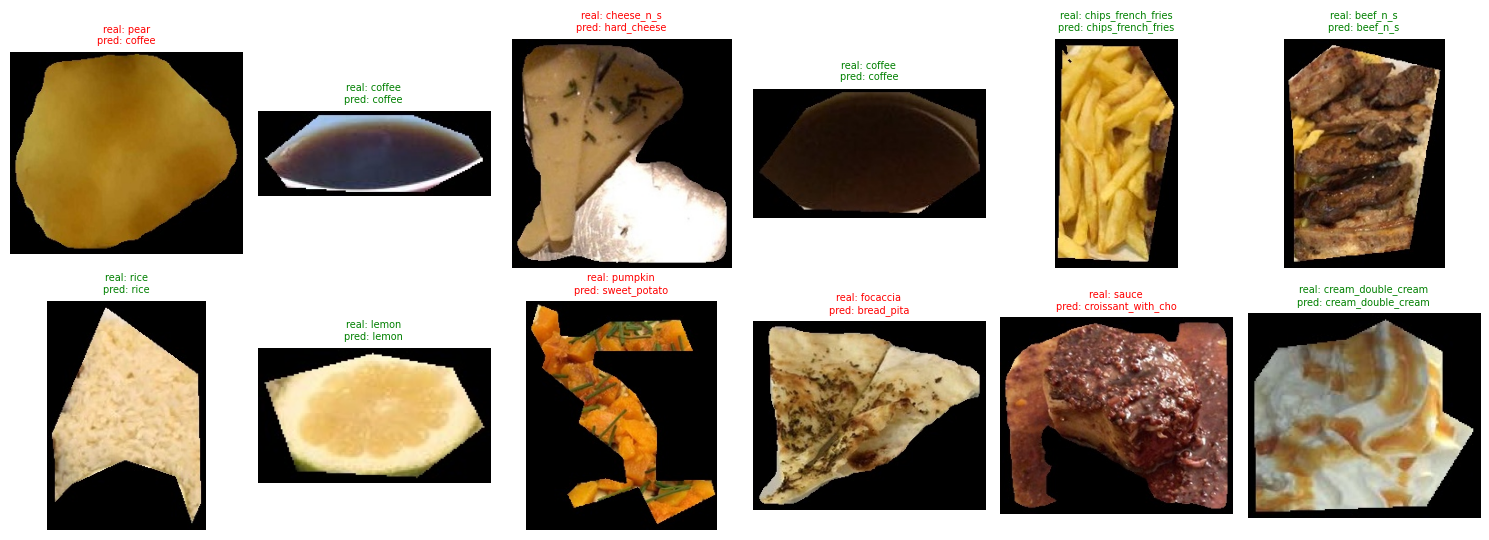

In [13]:
# Revisión cualitativa: 12 recortes de test con la clase real (verde = acierto, rojo = error)
try:
    import matplotlib.pyplot as plt
    from PIL import Image
    ids, y, p = OUTS["test"]; rows = CROPS["test"].set_index("ann_id").loc[ids[:12]]
    fig, axes = plt.subplots(2, 6, figsize=(15, 5.5))
    for ax, (aid, r), yi, pi in zip(axes.flat, rows.iterrows(), y[:12], p[:12]):
        ax.imshow(Image.open(r["file"])); ax.axis("off")
        ax.set_title(f"real: {prep.names[yi][:18]}\npred: {prep.names[int(pi.argmax())][:18]}", fontsize=7, color=("green" if pi.argmax() == yi else "red"))
    plt.tight_layout(); plt.show()
except Exception as e:
    print("Sin vista cualitativa:", type(e).__name__, e)

### Siguientes pasos
- Si el piloto salió bien: `CFG["pilot"] = False` y **Ejecutar todo**. Si Colab se desconecta, vuelve a ejecutar de arriba abajo con el mismo `CFG`: los recortes se vuelven a extraer en el disco local (unos minutos) y el entrenamiento **se reanuda solo** desde `last.pt` (o `last_prev.pt`) en Drive.
- Después: C4 (EfficientNetV2-S) con **esta misma plantilla**.
- **Alinear tamaños:** C3 usa `imgsz=224`; pon el mismo valor en C1, C2 y C4. El `RUN_NAME` **no** incluye el tamaño: si C1 o C2 ya entrenaron a 160, cambia su `base_id` (p. ej. `"C1_224"`) o borra su carpeta en `runs/`, o el cuaderno dará por terminado el run anterior y no reentrenará.
- Dónde queda todo (en `{WORK}`): `runs/C3_inception_v4/` (pesos, `history.csv`, `curvas.png`), `predicciones/` (probabilidades `.npz`, métricas por clase, matriz de confusión completa, `_metricas.json`) y `resultados/C3_inception_v4.json` (lo que lee el cuadernillo 99).